# PBL-1: Intelligent AgTech — Machine Learning Analysis

## Problem Statement

Agricultural decisions depend on soil and environmental conditions such as
Nitrogen (N), Phosphorus (P), Potassium (K), temperature, humidity, pH,
and rainfall.

In this project, machine learning techniques are applied to agricultural
data to:

1. Explore and understand the dataset through Exploratory Data Analysis (EDA).
2. Build regression models to predict rainfall.
3. Build classification models to predict the suitable crop.
4. Compare the performance of different machine learning models.
5. Interpret the results and identify the best-performing models.

### Dataset
The dataset contains soil and environmental parameters along with the crop label.

### Machine Learning Tasks
- **Regression Target:** Rainfall
- **Classification Target:** Crop Label

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

In [2]:
from pathlib import Path

# Find the project root from the current notebook working directory
current_dir = Path.cwd()

print("Current working directory:")
print(current_dir)

# Search for the dataset inside the project
matches = list(current_dir.rglob("crop_recommendation.csv"))

print("\nDataset files found:")
for file in matches:
    print(file)

Current working directory:
C:\Users\rajvi\Downloads\Harvestify-master 2

Dataset files found:
C:\Users\rajvi\Downloads\Harvestify-master 2\Data-processed\crop_recommendation.csv


In [3]:
# Load the crop recommendation dataset

data_path = r"Data-processed\crop_recommendation.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [4]:
# Dataset structure and data types

print("Dataset Information:")
print("-" * 50)

df.info()

Dataset Information:
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


In [5]:
# Descriptive statistics for numerical features

df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [6]:
# Check data quality

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


Number of unique crops: 22

Samples per crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64


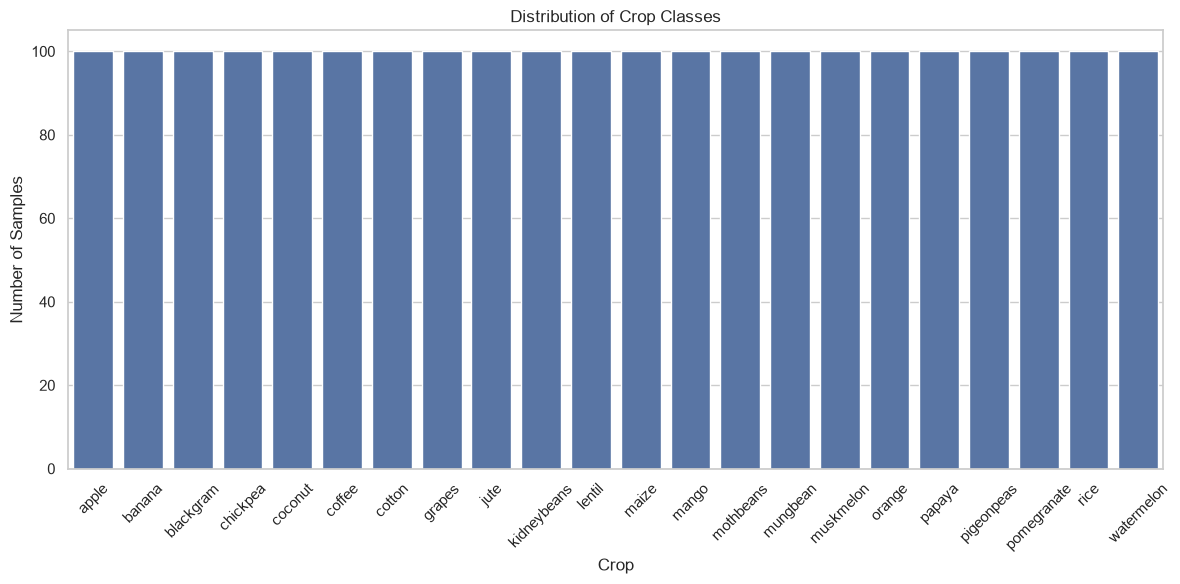

In [7]:
# Distribution of crop classes

crop_counts = df["label"].value_counts().sort_index()

print("Number of unique crops:", df["label"].nunique())
print("\nSamples per crop:")
print(crop_counts)

plt.figure(figsize=(12, 6))
sns.barplot(x=crop_counts.index, y=crop_counts.values)

plt.title("Distribution of Crop Classes")
plt.xlabel("Crop")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

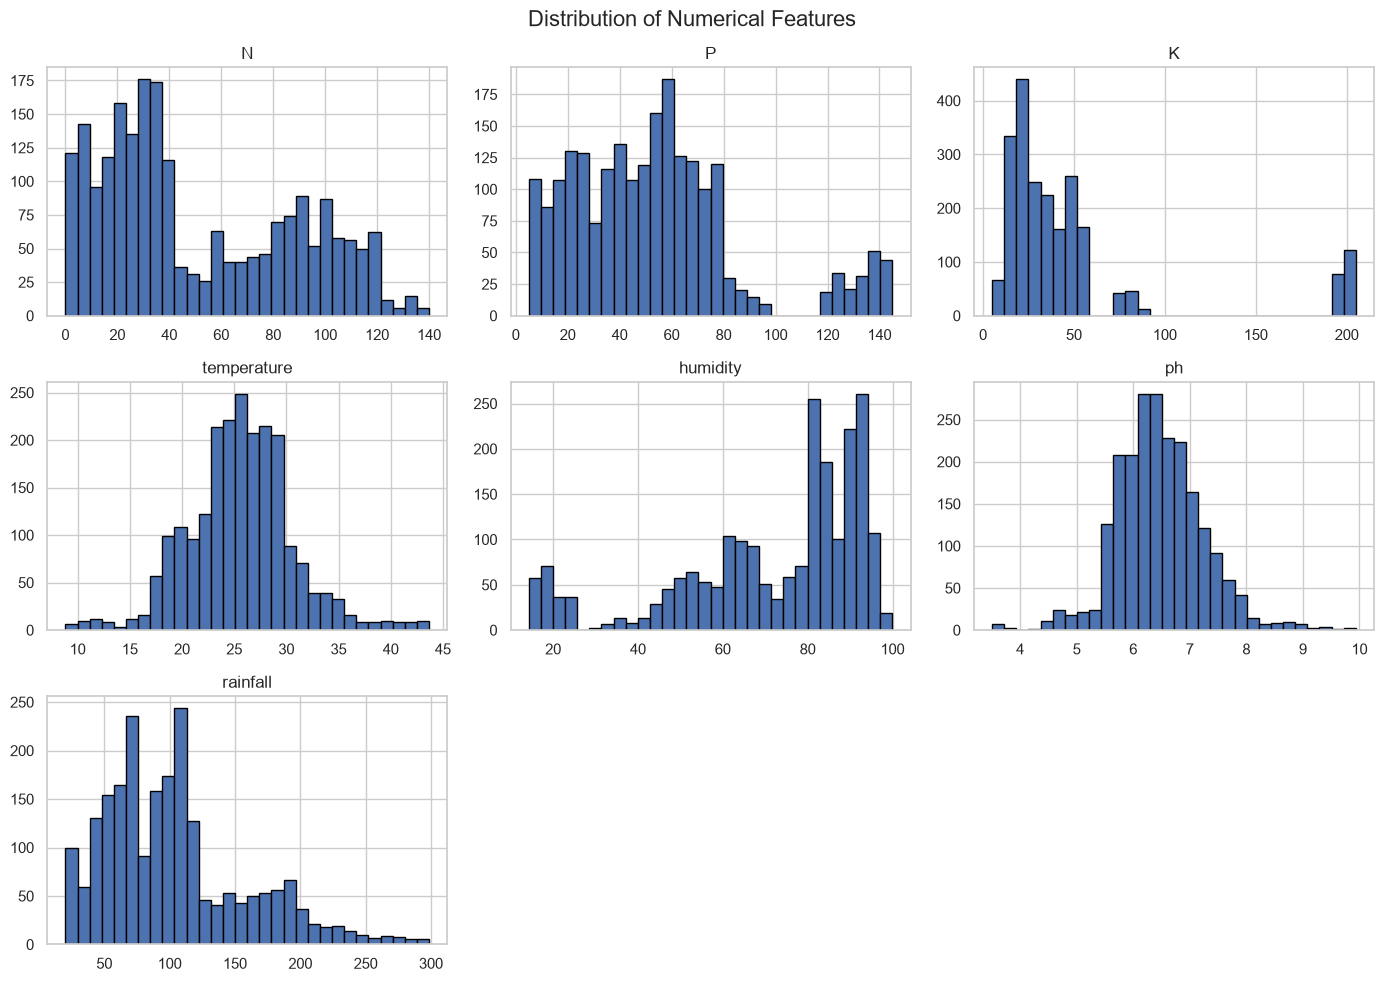

In [8]:
# Distribution of numerical features

numeric_features = [
    "N", "P", "K",
    "temperature", "humidity", "ph", "rainfall"
]

df[numeric_features].hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

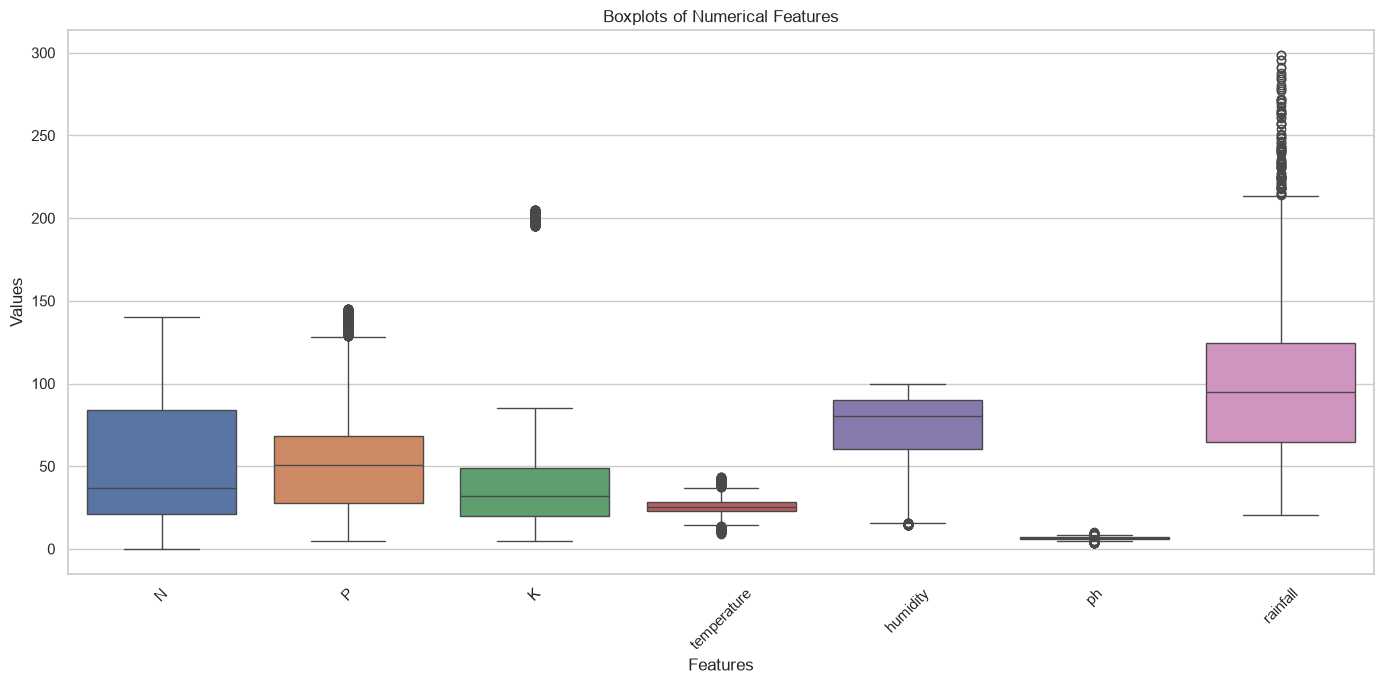

In [9]:
# Boxplots of numerical features

plt.figure(figsize=(14, 7))

sns.boxplot(data=df[numeric_features])

plt.title("Boxplots of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

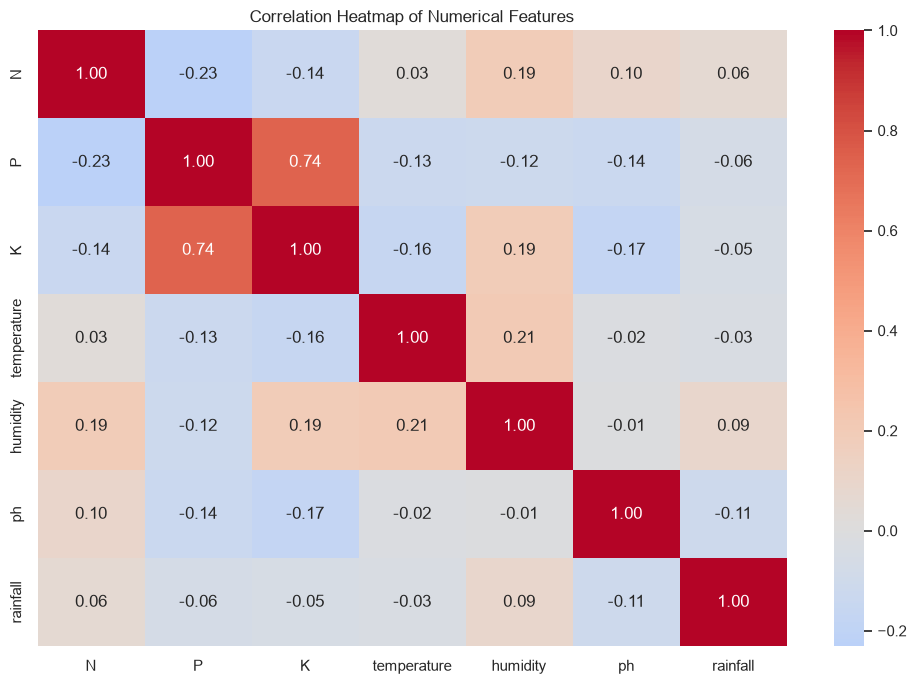

In [10]:
# Correlation between numerical features

plt.figure(figsize=(10, 7))

correlation_matrix = df[numeric_features].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

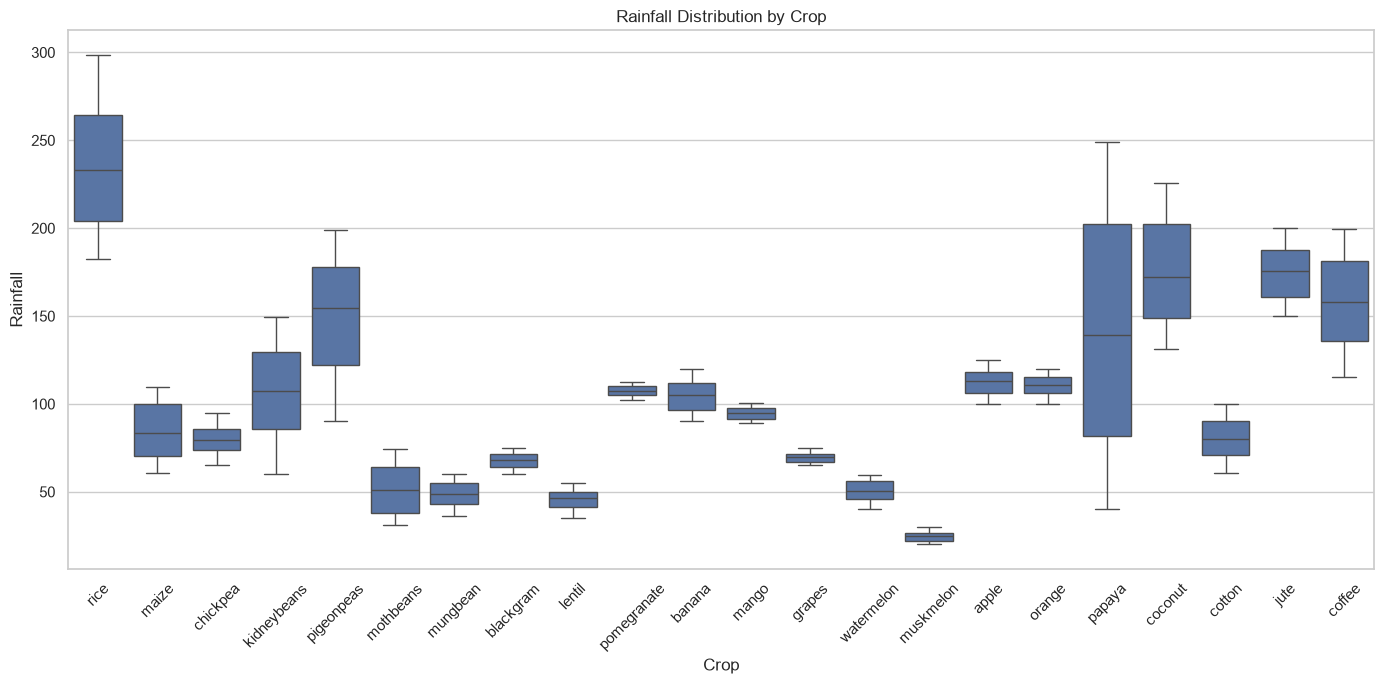

In [11]:
# Rainfall distribution across different crops

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="label",
    y="rainfall"
)

plt.title("Rainfall Distribution by Crop")
plt.xlabel("Crop")
plt.ylabel("Rainfall")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

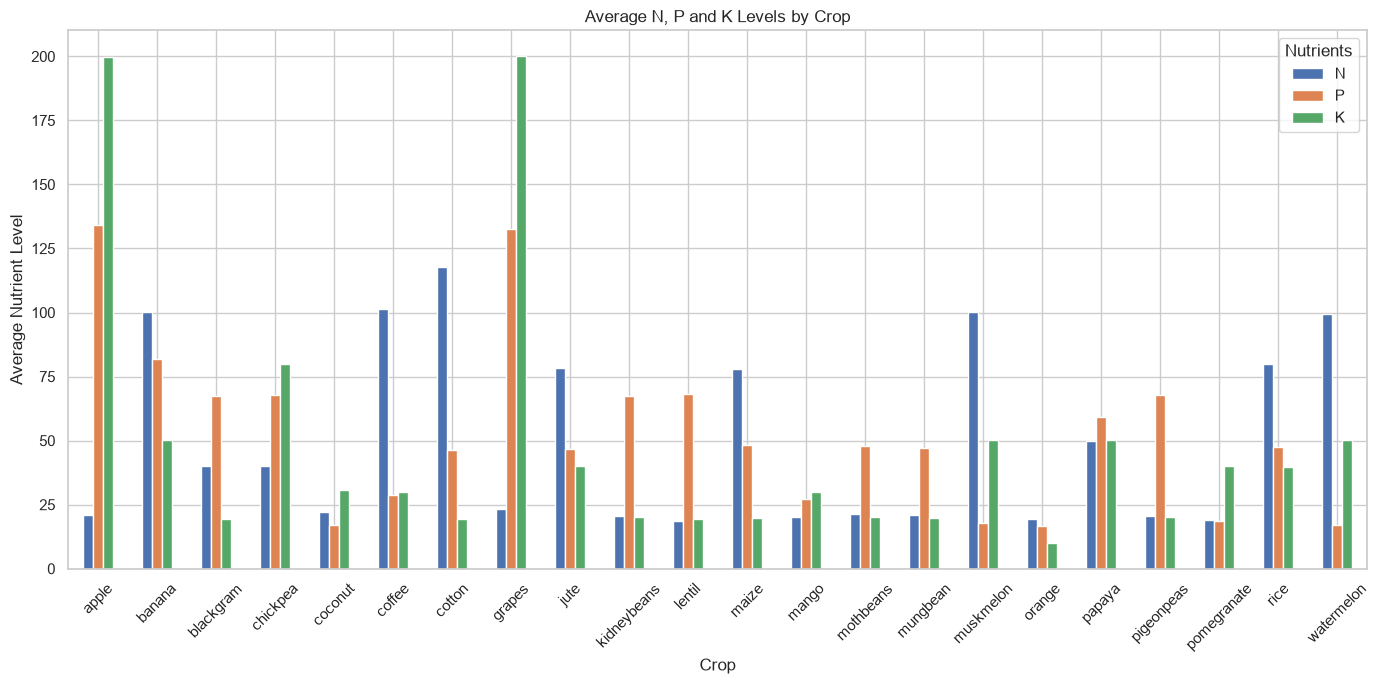

In [12]:
# Average soil nutrient levels by crop

nutrient_means = df.groupby("label")[["N", "P", "K"]].mean()

nutrient_means.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title("Average N, P and K Levels by Crop")
plt.xlabel("Crop")
plt.ylabel("Average Nutrient Level")
plt.xticks(rotation=45)
plt.legend(title="Nutrients")
plt.tight_layout()
plt.show()

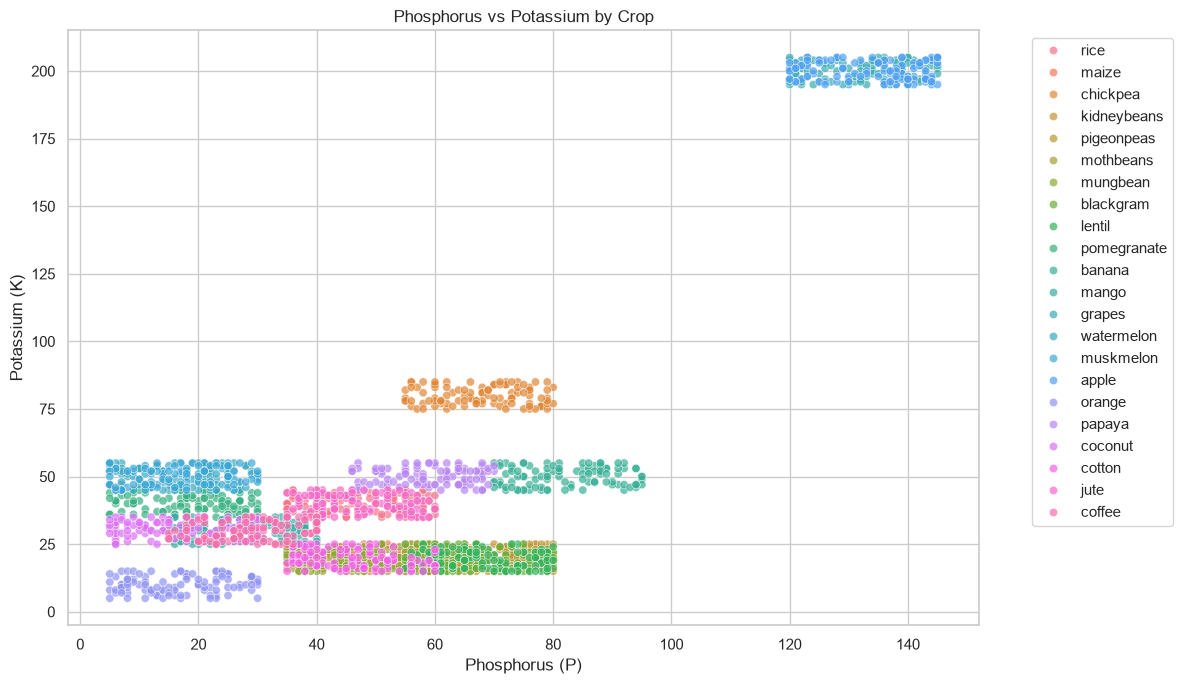

In [13]:
# Relationship between Phosphorus and Potassium

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="P",
    y="K",
    hue="label",
    alpha=0.7
)

plt.title("Phosphorus vs Potassium by Crop")
plt.xlabel("Phosphorus (P)")
plt.ylabel("Potassium (K)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

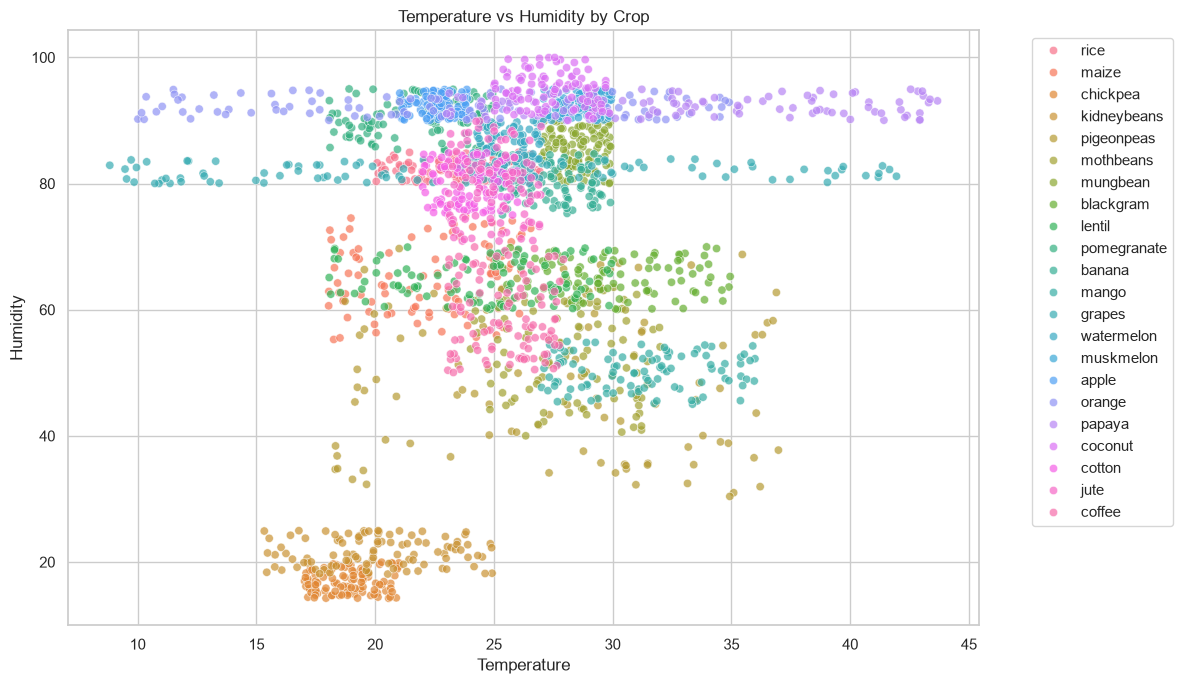

In [14]:
# Temperature vs Humidity by Crop

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity",
    hue="label",
    alpha=0.7
)

plt.title("Temperature vs Humidity by Crop")
plt.xlabel("Temperature")
plt.ylabel("Humidity")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## EDA Insights

The exploratory analysis revealed several important patterns in the dataset:

1. **Balanced classes:** The dataset contains 22 crop classes with exactly 100 samples per class, so there is no class imbalance.

2. **Data quality:** The dataset contains no missing values and no duplicate observations.

3. **Feature distributions:** The numerical variables have different ranges and distributions. Temperature and pH are relatively concentrated, while N, P, K and rainfall show more variation.

4. **Feature relationships:** Phosphorus and potassium show a relatively strong positive correlation (approximately 0.74). Most other numerical feature pairs have weak linear correlations.

5. **Crop-specific rainfall patterns:** Rainfall distributions vary considerably across crops, indicating that rainfall contains useful information for distinguishing crop classes.

6. **Nutrient differences:** Average N, P and K levels vary substantially between crops, indicating crop-specific nutrient requirements.

7. **Feature clustering:** The P-K and temperature-humidity scatter plots show distinct clusters for several crops, although some classes overlap.

8. **Outlier interpretation:** Some features contain observations outside the standard boxplot whiskers. These were retained because they may represent legitimate crop-specific conditions rather than data-entry errors.

Overall, the EDA suggests that crop classification can benefit from combining multiple soil and environmental features rather than relying on a single variable.

## Regression Analysis

### Objective

The regression task aims to predict **rainfall**, which is a continuous numerical variable.

The dataset does not contain a natural continuous agricultural outcome such as crop yield. Therefore, rainfall is selected as the regression target.

### Features

The following variables are used as predictors:

- N — Nitrogen
- P — Phosphorus
- K — Potassium
- Temperature
- Humidity
- pH

The crop `label` is excluded from regression because it is categorical.

### Models

Three regression algorithms will be compared:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

### Evaluation Metrics

The models will be evaluated using:

- MAE (Mean Absolute Error)
- MSE (Mean Squared Error)
- RMSE (Root Mean Squared Error)
- R² Score
- 5-Fold Cross-Validation R²

In [16]:
# Prepare data for regression

regression_features = [
    "N", "P", "K",
    "temperature", "humidity", "ph"
]

X_reg = df[regression_features]
y_reg = df["rainfall"]

# 80/20 train-test split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Regression data prepared.")
print("Training samples:", X_reg_train.shape[0])
print("Testing samples:", X_reg_test.shape[0])
print("Number of features:", X_reg_train.shape[1])

Regression data prepared.
Training samples: 1760
Testing samples: 440
Number of features: 6


In [17]:
# Model 1: Linear Regression

linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_reg_train, y_reg_train)

y_linear_pred = linear_model.predict(X_reg_test)

linear_mae = mean_absolute_error(y_reg_test, y_linear_pred)
linear_mse = mean_squared_error(y_reg_test, y_linear_pred)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_reg_test, y_linear_pred)
linear_train_r2 = r2_score(
    y_reg_train,
    linear_model.predict(X_reg_train)
)

print("Linear Regression Results")
print("-" * 35)
print(f"MAE:      {linear_mae:.4f}")
print(f"MSE:      {linear_mse:.4f}")
print(f"RMSE:     {linear_rmse:.4f}")
print(f"Test R²:  {linear_r2:.4f}")
print(f"Train R²: {linear_train_r2:.4f}")

Linear Regression Results
-----------------------------------
MAE:      41.2479
MSE:      2973.0491
RMSE:     54.5257
Test R²:  0.0124
Train R²: 0.0396


In [26]:
# Model 2: Decision Tree Regression

dt_regressor = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=3,
    random_state=42
)

dt_regressor.fit(X_reg_train, y_reg_train)

y_dt_pred = dt_regressor.predict(X_reg_test)

dt_mae = mean_absolute_error(y_reg_test, y_dt_pred)
dt_mse = mean_squared_error(y_reg_test, y_dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_reg_test, y_dt_pred)
dt_train_r2 = r2_score(
    y_reg_train,
    dt_regressor.predict(X_reg_train)
)

print("Decision Tree Regression Results")
print("-" * 40)
print(f"MAE:      {dt_mae:.4f}")
print(f"MSE:      {dt_mse:.4f}")
print(f"RMSE:     {dt_rmse:.4f}")
print(f"Test R²:  {dt_r2:.4f}")
print(f"Train R²: {dt_train_r2:.4f}")

Decision Tree Regression Results
----------------------------------------
MAE:      18.0219
MSE:      915.7371
RMSE:     30.2611
Test R²:  0.6958
Train R²: 0.9316


In [27]:
# Model 3: Random Forest Regression

rf_regressor = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_regressor.fit(X_reg_train, y_reg_train)

y_rf_pred = rf_regressor.predict(X_reg_test)

rf_mae = mean_absolute_error(y_reg_test, y_rf_pred)
rf_mse = mean_squared_error(y_reg_test, y_rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_reg_test, y_rf_pred)
rf_train_r2 = r2_score(
    y_reg_train,
    rf_regressor.predict(X_reg_train)
)

print("Random Forest Regression Results")
print("-" * 40)
print(f"MAE:      {rf_mae:.4f}")
print(f"MSE:      {rf_mse:.4f}")
print(f"RMSE:     {rf_rmse:.4f}")
print(f"Test R²:  {rf_r2:.4f}")
print(f"Train R²: {rf_train_r2:.4f}")

Random Forest Regression Results
----------------------------------------
MAE:      16.8786
MSE:      763.2224
RMSE:     27.6265
Test R²:  0.7465
Train R²: 0.9718


In [28]:
# Regression model comparison

regression_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        dt_mae,
        rf_mae
    ],
    "RMSE": [
        linear_rmse,
        dt_rmse,
        rf_rmse
    ],
    "R2": [
        linear_r2,
        dt_r2,
        rf_r2
    ]
})

regression_results

,Model,MAE,RMSE,R2
0,Linear Regression,41.247926,54.525674,0.012393
1,Decision Tree,18.021940,30.261148,0.695804
2,Random Forest,16.878601,27.626480,0.746468


In [29]:
# 5-Fold Cross-Validation for Regression Models

kf = KFold(n_splits=5, shuffle=True, random_state=42)

regression_models = {
    "Linear Regression": linear_model,
    "Decision Tree": dt_regressor,
    "Random Forest": rf_regressor
}

cv_results = []

for name, model in regression_models.items():
    scores = cross_val_score(
        model,
        X_reg,
        y_reg,
        cv=kf,
        scoring="r2"
    )
    
    cv_results.append({
        "Model": name,
        "CV Mean R²": scores.mean(),
        "CV Std": scores.std()
    })

regression_cv_results = pd.DataFrame(cv_results)

regression_cv_results

,Model,CV Mean R²,CV Std
0,Linear Regression,0.026519,0.020627
1,Decision Tree,0.679225,0.054699
2,Random Forest,0.778076,0.032780


In [31]:
# Combine test-set and cross-validation results

regression_comparison = regression_results.merge(
    regression_cv_results,
    on="Model"
)

regression_comparison

,Model,MAE,RMSE,R2,CV Mean R²,CV Std
0,Linear Regression,41.247926,54.525674,0.012393,0.026519,0.020627
1,Decision Tree,18.021940,30.261148,0.695804,0.679225,0.054699
2,Random Forest,16.878601,27.626480,0.746468,0.778076,0.032780


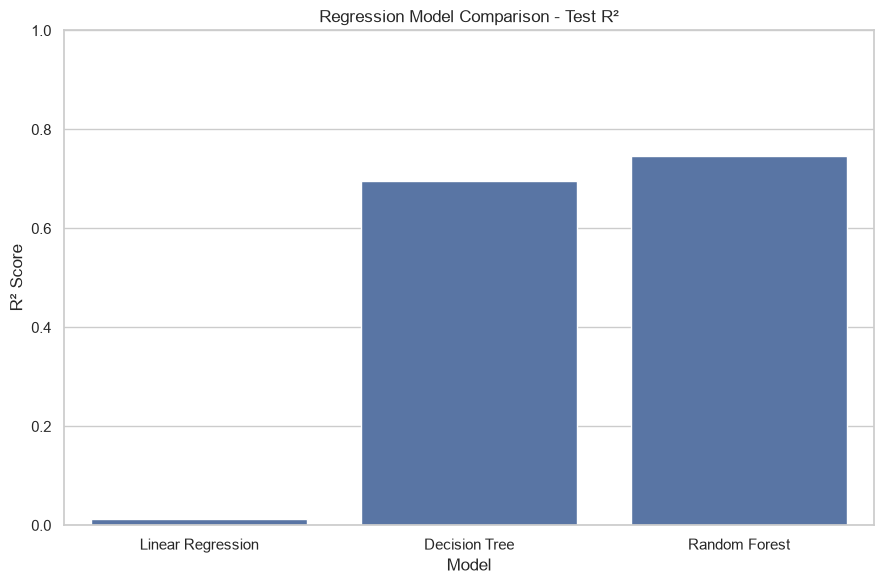

In [32]:
# Compare regression models using Test R²

plt.figure(figsize=(9, 6))

sns.barplot(
    data=regression_comparison,
    x="Model",
    y="R2"
)

plt.title("Regression Model Comparison - Test R²")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

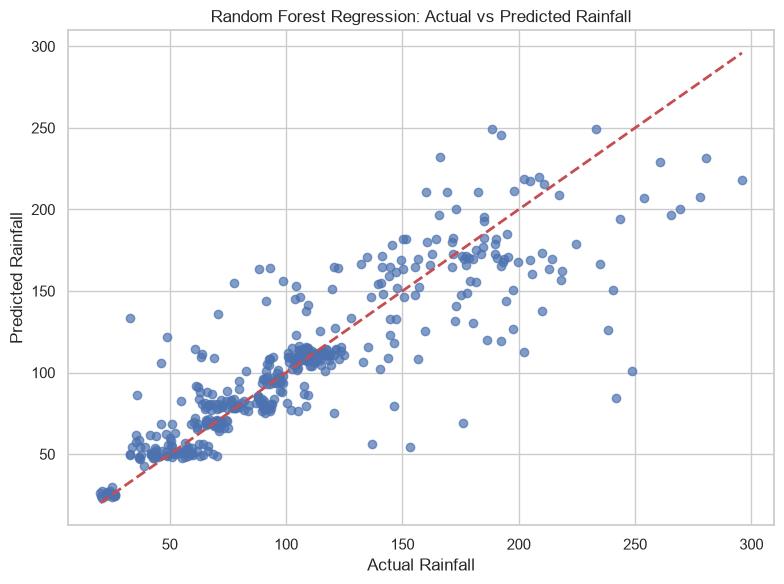

In [33]:
plt.figure(figsize=(8, 6))

plt.scatter(y_reg_test, y_rf_pred, alpha=0.7)

plt.plot(
    [y_reg_test.min(), y_reg_test.max()],
    [y_reg_test.min(), y_reg_test.max()],
    "r--",
    linewidth=2
)

plt.title("Random Forest Regression: Actual vs Predicted Rainfall")
plt.xlabel("Actual Rainfall")
plt.ylabel("Predicted Rainfall")

plt.tight_layout()
plt.show()

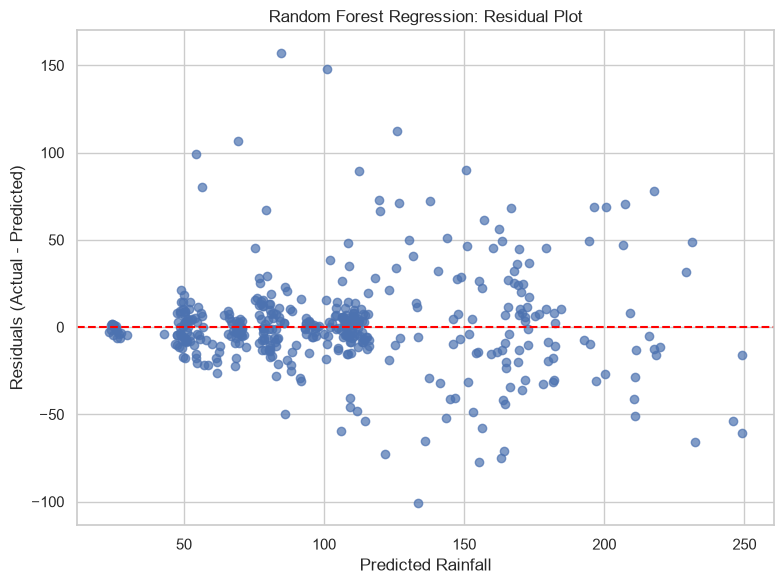

In [34]:
rf_residuals = y_reg_test - y_rf_pred

plt.figure(figsize=(8, 6))

plt.scatter(y_rf_pred, rf_residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")

plt.title("Random Forest Regression: Residual Plot")
plt.xlabel("Predicted Rainfall")
plt.ylabel("Residuals (Actual - Predicted)")

plt.tight_layout()
plt.show()
plt.show()

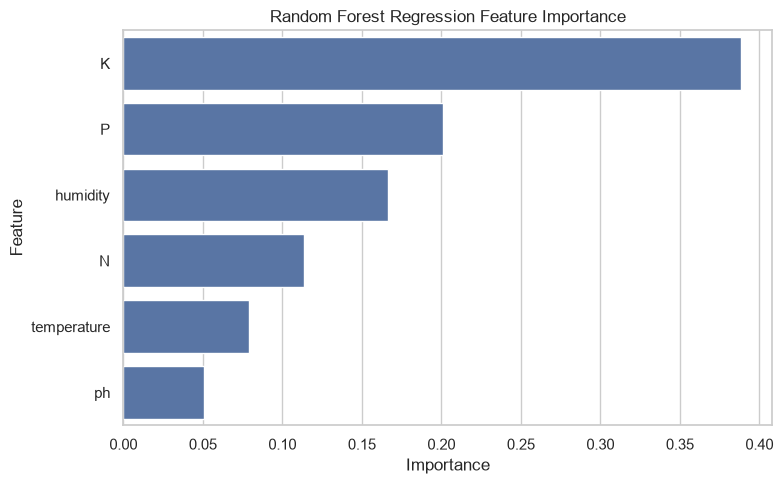

In [35]:
rf_reg_importance = pd.Series(
    rf_regressor.feature_importances_,
    index=regression_features
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rf_reg_importance.values,
    y=rf_reg_importance.index
)

plt.title("Random Forest Regression Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## Regression Results and Interpretation

The three regression models showed clear differences in performance.

- **Linear Regression** performed poorly, with a test R² of **0.0124** and a 5-fold CV R² of **0.0265**, indicating that a simple linear relationship is not sufficient to predict rainfall.
- **Decision Tree Regression** performed substantially better, achieving a test R² of **0.6958** and a CV R² of **0.6792**.
- **Random Forest Regression** achieved the best overall performance, with the lowest MAE (**16.8786**), lowest RMSE (**27.6265**), and highest test R² (**0.7465**). Its 5-fold CV R² was **0.7781**.

The Random Forest feature importance analysis shows that **Potassium (K)** was the most influential feature, followed by **Phosphorus (P)** and **humidity**.

Overall, the tree-based models performed much better than Linear Regression, suggesting that the relationships between the input features and rainfall are not purely linear. The difference between training and test performance also indicates some degree of overfitting, although the cross-validation results support the Random Forest model's overall robustness.

In [ ]:
## Classification Analysis

### Objective

The classification task aims to predict the **suitable crop** based on soil and environmental conditions.

### Target

- **Target variable:** `label` (crop type)

### Features

The following seven numerical features are used:

- N — Nitrogen
- P — Phosphorus
- K — Potassium
- Temperature
- Humidity
- pH
- Rainfall

### Models

Three classification algorithms will be compared:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier

### Evaluation Metrics

The models will be evaluated using:

- Accuracy
- Macro Precision
- Macro Recall
- Macro F1-Score
- Training Accuracy
- 5-Fold Stratified Cross-Validation Accuracy

In [36]:
classification_features = [
    "N", "P", "K",
    "temperature", "humidity", "ph", "rainfall"
]

X_cls = df[classification_features]
y_cls = df["label"]

X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

print("Classification data prepared.")
print("Training samples:", X_cls_train.shape[0])
print("Testing samples:", X_cls_test.shape[0])
print("Number of features:", X_cls_train.shape[1])
print("Number of classes:", y_cls.nunique())

Classification data prepared.
Training samples: 1760
Testing samples: 440
Number of features: 7
Number of classes: 22


In [37]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

logistic_model.fit(X_cls_train, y_cls_train)

y_logistic_pred = logistic_model.predict(X_cls_test)

logistic_accuracy = accuracy_score(y_cls_test, y_logistic_pred)
logistic_precision = precision_score(
    y_cls_test, y_logistic_pred, average="macro"
)
logistic_recall = recall_score(
    y_cls_test, y_logistic_pred, average="macro"
)
logistic_f1 = f1_score(
    y_cls_test, y_logistic_pred, average="macro"
)
logistic_train_accuracy = accuracy_score(
    y_cls_train, logistic_model.predict(X_cls_train)
)

print("Logistic Regression Results")
print("-" * 35)
print(f"Test Accuracy:       {logistic_accuracy:.4f}")
print(f"Macro Precision:     {logistic_precision:.4f}")
print(f"Macro Recall:        {logistic_recall:.4f}")
print(f"Macro F1-Score:      {logistic_f1:.4f}")
print(f"Training Accuracy:   {logistic_train_accuracy:.4f}")

Logistic Regression Results
-----------------------------------
Test Accuracy:       0.9727
Macro Precision:     0.9740
Macro Recall:        0.9727
Macro F1-Score:      0.9725
Training Accuracy:   0.9739


In [38]:
dt_classifier = DecisionTreeClassifier(
    random_state=42
)

dt_classifier.fit(X_cls_train, y_cls_train)

y_dt_cls_pred = dt_classifier.predict(X_cls_test)

dt_cls_accuracy = accuracy_score(y_cls_test, y_dt_cls_pred)
dt_cls_precision = precision_score(
    y_cls_test, y_dt_cls_pred, average="macro"
)
dt_cls_recall = recall_score(
    y_cls_test, y_dt_cls_pred, average="macro"
)
dt_cls_f1 = f1_score(
    y_cls_test, y_dt_cls_pred, average="macro"
)
dt_cls_train_accuracy = accuracy_score(
    y_cls_train, dt_classifier.predict(X_cls_train)
)

print("Decision Tree Classifier Results")
print("-" * 40)
print(f"Test Accuracy:       {dt_cls_accuracy:.4f}")
print(f"Macro Precision:     {dt_cls_precision:.4f}")
print(f"Macro Recall:        {dt_cls_recall:.4f}")
print(f"Macro F1-Score:      {dt_cls_f1:.4f}")
print(f"Training Accuracy:   {dt_cls_train_accuracy:.4f}")

Decision Tree Classifier Results
----------------------------------------
Test Accuracy:       0.9795
Macro Precision:     0.9806
Macro Recall:        0.9795
Macro F1-Score:      0.9794
Training Accuracy:   1.0000


In [39]:
rf_classifier = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_classifier.fit(X_cls_train, y_cls_train)

y_rf_cls_pred = rf_classifier.predict(X_cls_test)

rf_cls_accuracy = accuracy_score(y_cls_test, y_rf_cls_pred)
rf_cls_precision = precision_score(
    y_cls_test, y_rf_cls_pred, average="macro"
)
rf_cls_recall = recall_score(
    y_cls_test, y_rf_cls_pred, average="macro"
)
rf_cls_f1 = f1_score(
    y_cls_test, y_rf_cls_pred, average="macro"
)
rf_cls_train_accuracy = accuracy_score(
    y_cls_train, rf_classifier.predict(X_cls_train)
)

print("Random Forest Classifier Results")
print("-" * 42)
print(f"Test Accuracy:       {rf_cls_accuracy:.4f}")
print(f"Macro Precision:     {rf_cls_precision:.4f}")
print(f"Macro Recall:        {rf_cls_recall:.4f}")
print(f"Macro F1-Score:      {rf_cls_f1:.4f}")
print(f"Training Accuracy:   {rf_cls_train_accuracy:.4f}")

Random Forest Classifier Results
------------------------------------------
Test Accuracy:       0.9955
Macro Precision:     0.9957
Macro Recall:        0.9955
Macro F1-Score:      0.9955
Training Accuracy:   1.0000


In [40]:
classification_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        dt_cls_accuracy,
        rf_cls_accuracy
    ],
    "Macro Precision": [
        logistic_precision,
        dt_cls_precision,
        rf_cls_precision
    ],
    "Macro Recall": [
        logistic_recall,
        dt_cls_recall,
        rf_cls_recall
    ],
    "Macro F1": [
        logistic_f1,
        dt_cls_f1,
        rf_cls_f1
    ]
})

classification_results

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Logistic Regression,0.972727,0.974022,0.972727,0.972464
1,Decision Tree,0.979545,0.980598,0.979545,0.979423
2,Random Forest,0.995455,0.995671,0.995455,0.995452


In [42]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

classification_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": dt_classifier,
    "Random Forest": rf_classifier
}

classification_cv_results = []

for name, model in classification_models.items():
    scores = cross_val_score(
        model,
        X_cls,
        y_cls,
        cv=skf,
        scoring="accuracy"
    )

    classification_cv_results.append({
        "Model": name,
        "CV Mean Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

classification_cv_results = pd.DataFrame(classification_cv_results)

classification_cv_results

,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.970909,0.002227
1,Decision Tree,0.987727,0.006833
2,Random Forest,0.995909,0.002650


In [44]:
classification_comparison = classification_results.merge(
    classification_cv_results,
    on="Model"
)

classification_comparison

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,CV Mean Accuracy,CV Std
0,Logistic Regression,0.972727,0.974022,0.972727,0.972464,0.970909,0.002227
1,Decision Tree,0.979545,0.980598,0.979545,0.979423,0.987727,0.006833
2,Random Forest,0.995455,0.995671,0.995455,0.995452,0.995909,0.002650


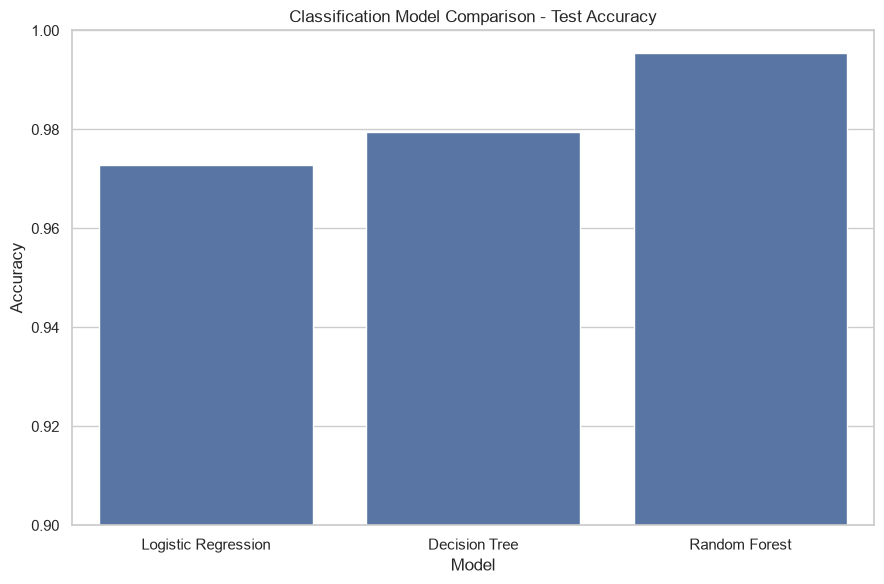

In [46]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=classification_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Classification Model Comparison - Test Accuracy")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.00)

plt.tight_layout()
plt.show()

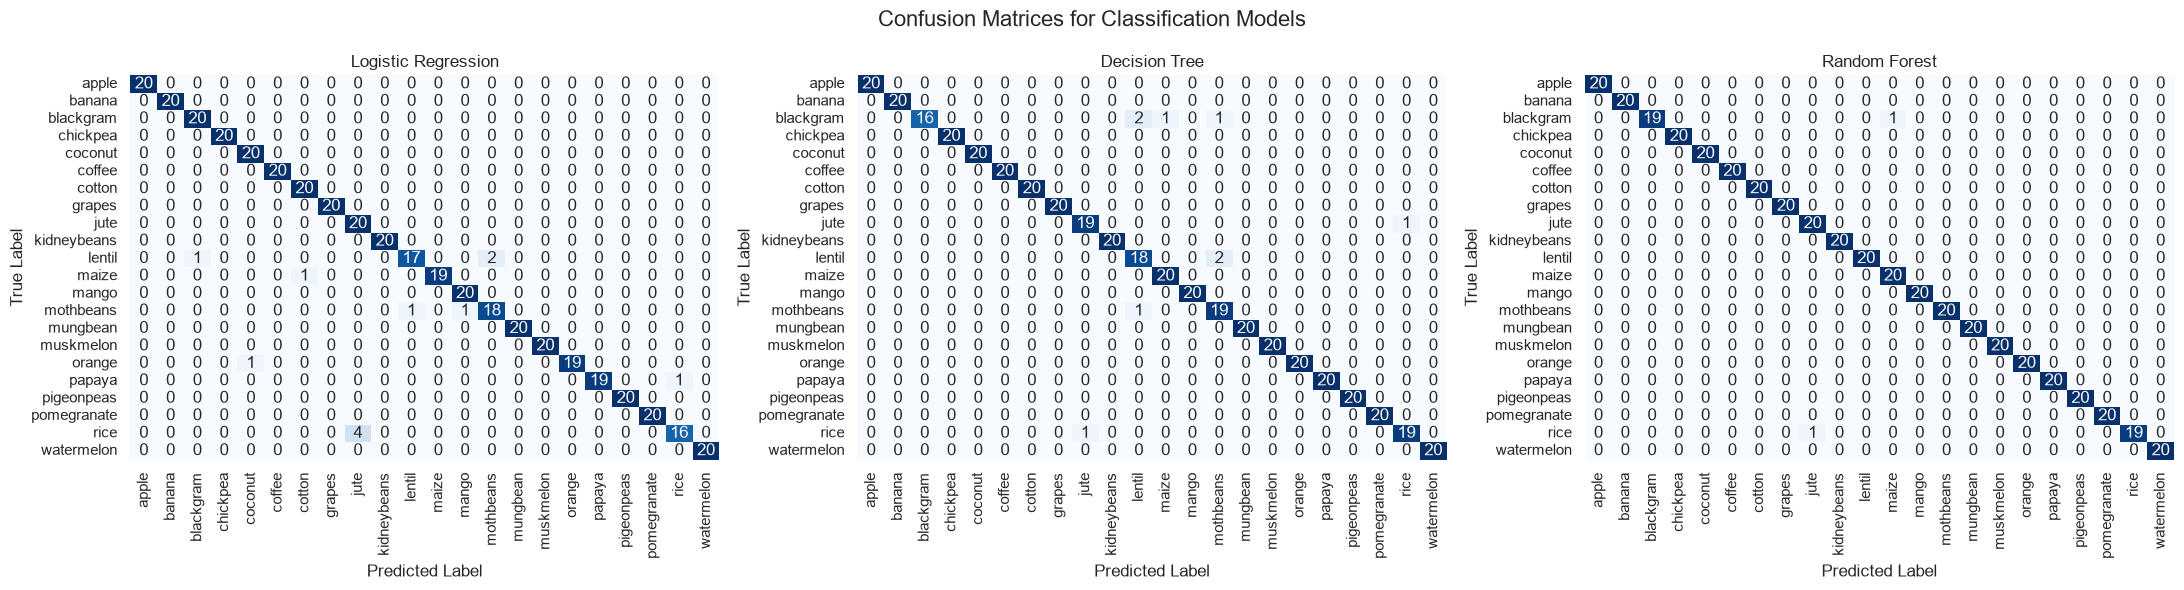

In [47]:
class_names = sorted(y_cls.unique())

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

models_and_predictions = [
    ("Logistic Regression", y_logistic_pred),
    ("Decision Tree", y_dt_cls_pred),
    ("Random Forest", y_rf_cls_pred)
]

for ax, (name, predictions) in zip(axes, models_and_predictions):
    cm = confusion_matrix(
        y_cls_test,
        predictions,
        labels=class_names
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
        cbar=False
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices for Classification Models", fontsize=16)
plt.tight_layout()
plt.show()

In [48]:
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_cls_test, y_logistic_pred))

print("\nDECISION TREE - CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_cls_test, y_dt_cls_pred))

print("\nRANDOM FOREST - CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_cls_test, y_rf_cls_pred))

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       0.95      1.00      0.98        20
    chickpea       1.00      1.00      1.00        20
     coconut       0.95      1.00      0.98        20
      coffee       1.00      1.00      1.00        20
      cotton       0.95      1.00      0.98        20
      grapes       1.00      1.00      1.00        20
        jute       0.83      1.00      0.91        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.94      0.85      0.89        20
       maize       1.00      0.95      0.97        20
       mango       0.95      1.00      0.98        20
   mothbeans       0.90      0.90      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      0.95    

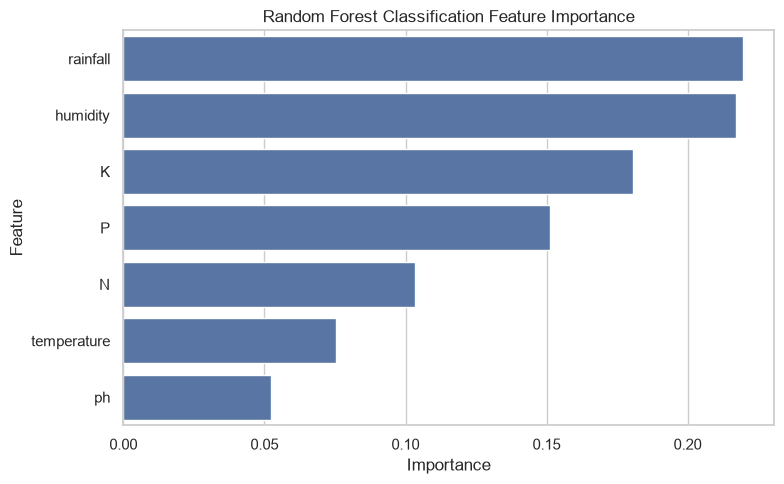

In [49]:
rf_cls_importance = pd.Series(
    rf_classifier.feature_importances_,
    index=classification_features
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=rf_cls_importance.values,
    y=rf_cls_importance.index
)

plt.title("Random Forest Classification Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

## 


















Classification Results and Interpretation

The three classification models achieved strong performance on the test dataset.

- **Logistic Regression** achieved a test accuracy of **97.27%** and a macro F1-score of **97.25%**.
- **Decision Tree Classifier** improved the test accuracy to **97.95%** with a macro F1-score of **97.94%**.
- **Random Forest Classifier** achieved the best performance with a test accuracy of **99.55%** and a macro F1-score of **99.55%**.

The 5-fold Stratified Cross-Validation results also support this conclusion. Random Forest achieved a mean accuracy of **99.59% ± 0.27%**, compared with **98.77% ± 0.68%** for Decision Tree and **97.09% ± 0.22%** for Logistic Regression.

The confusion matrices show that Random Forest produced very few misclassifications across the 22 crop classes.

Feature importance analysis indicates that **rainfall and humidity** were the most influential features for Random Forest classification, followed by **potassium (K)** and **phosphorus (P)**.

Overall, Random Forest was the best-performing classification model because it achieved the highest test accuracy, macro F1-score, and cross-validation accuracy.

## Overall Conclusion

This project applied machine learning techniques to agricultural soil and environmental data for both regression and classification tasks.

For regression, rainfall was selected as the continuous target because the dataset does not contain a natural agricultural outcome such as crop yield. Among the three regression models, **Random Forest Regressor** performed best, achieving a test R² of **0.7465**, RMSE of **27.6265**, and a 5-fold CV R² of **0.7781**.

For classification, the objective was to predict the suitable crop from seven soil and environmental features. Among the three classification models, **Random Forest Classifier** performed best, achieving **99.55% test accuracy**, **99.55% macro F1-score**, and **99.59% ± 0.27% cross-validation accuracy**.

Overall, the results show that tree-based ensemble methods were more effective than the linear models for this dataset, indicating the presence of nonlinear relationships between the agricultural features and the prediction targets.

### Dataset Limitation

The dataset used in this project is a custom/synthetic agricultural dataset. Therefore, the high classification performance should not be interpreted as equivalent to real-world agricultural prediction accuracy. Further validation using real field data would be required before deploying such a model in practical agricultural decision-making.